# Explanations that stay put: seeds, reason codes, Shapley additivity, partial dependence and accumulated local effects

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 02 of this topic
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- measure how much a model's AUC, the grades it assigns and the ranking of its attributions move when only the training seed changes, and read each against its convention;
- explain what a reason code is (a signed contribution toward default), measure how stable the top four are across refits, and say why the sign matters;
- check that Shapley attributions add up to the prediction, and see the check fail when they do not;
- compute partial dependence, individual conditional expectation (ICE) and accumulated local effects (ALE) for a model given as a function, check their identities, and compare two explainers by rank agreement and by the sign and monotonicity of an effect;
- read the committed seed sweep of case C20 and rebuild its rows with the engine.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the packages and print their versions
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ml import effects, explanations, plants, seeds
from riskvalidation.ml.explanations import OverlapResult
from riskvalidation.ml.seeds import SeedDispersion
from riskvalidation.validation import discrimination as disc
from riskvalidation.validation import ml as vml
from scipy import special

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

- **The seed-unstable plant** of the engine (`SeedUnstablePlant`): defaulters and survivors separated by a signal column, a pure-noise column, and a model whose weight on the noise column changes with the training seed by an amount we choose (`instability`). The mean and the spread of the AUC across seeds are known by quadrature, so the test can be checked against the truth.
- **A family of linear-logit models** written in this notebook: eight features, a base coefficient vector and one coefficient vector per seed or refit that moves around the base by a chosen amount. For a linear model on the log-odds the Shapley value of feature $j$ has a closed form, $\phi_{ij} = \beta_j (x_{ij} - \bar{x}_j)$ (Lundberg and Lee, 2017, for independent features), so the attributions are exact and the engine's checks can be read against a known answer. This is data for the engine's functions; the notebook implements none of them.
- **The committed seed sweep of case C20** (`data/derived/C20/seed-sweep.json`; owner: this repository, derived from the UCI Taiwan credit-card data, CC BY 4.0, class mirror-allowed): a LightGBM and an XGBoost model refitted with 20 seeds, 100 bootstrap refits for the reason codes and an ALE curve for each leading feature. The pipeline computed the TreeSHAP attributions with the pinned `shap` and handed arrays to the engine; the engine never imports `shap` or the learners. The next cell opens the document.

In [2]:
# Open the committed seed sweep and print the engine that baked it and its rows
sweep = json.loads((ROOT / "data" / "derived" / "C20" / "seed-sweep.json").read_text(encoding="utf-8"))
print("baked with riskvalidation", sweep["provenance"]["riskvalidation_version"], "| test rows", len(sweep["tests"]))
for row in sweep["outputs"]["rows"]:
    print(f'{row["rung"]:14s} seeds {row["n_seeds"]} | AUC mean {row["auc"]["mean"]:.4f} sd {row["auc"]["sd"]:.5f} | share of obligors whose grade changes {row["grade_assignment_changed_share"]:.4f}')

baked with riskvalidation 0.9.0 | test rows 22
P4-lightgbm    seeds 20 | AUC mean 0.7774 sd 0.00105 | share of obligors whose grade changes 0.6221
P4-xgboost     seeds 20 | AUC mean 0.7761 sd 0.00079 | share of obligors whose grade changes 0.5672


## Method

The ECB guide asks a validator to check the randomness of the training process, the stability of the explanations and the agreement of the explainers (paragraphs 43, 59, 62, 64 to 66; see the references). The engine turns each into a number and, where it can, a light. All cut points are conventions.

### Step 1: the AUC across training seeds

A model trained twice from different seeds is two models. The test refits the model with $S \ge 2$ distinct seeds, scores each on the same rows and reports the mean, the minimum, the maximum and the **sample standard deviation** (ddof 1) of the AUC:

$$\mathrm{sd}_{\mathrm{AUC}} = \sqrt{\frac{1}{S-1}\sum_{s=1}^{S}\bigl(\mathrm{AUC}_s - \overline{\mathrm{AUC}}\bigr)^2}.$$

The light is green below 0.01, amber from 0.01 and red from 0.02 (about the sampling standard error of a Taiwan holdout AUC). The engine takes the training function as a callable `train(seed) -> predict`, which the plant provides. The next cell runs 20 seeds on a plant with an instability of 0.6 and on the stable plant (instability 0), and prints the engine's dispersion beside the exact one.

In [3]:
# AUC dispersion over 20 training seeds on an unstable plant and on a stable one, against the exact values
SEEDS = list(range(20))
dispersion = {}
for label, instability in (("unstable", 0.6), ("stable", 0.0)):
    plant = plants.SeedUnstablePlant(n=5000, instability=instability, seed=4)
    data = plant.sample()
    disp = seeds.seed_auc_dispersion(plant.train, data["X"], data["y"], SEEDS)
    exact = plant.truth()
    result = vml.seed_stability("seed-plant", disp)
    dispersion[label] = (plant, data, disp)
    print(f"{label:11s} AUC mean {disp.mean:.4f} (exact {exact['mean_auc']:.4f}) | sd {disp.sd:.5f} (exact {exact['sd_auc_across_seeds']:.5f}) | range {disp.minimum:.4f} {disp.maximum:.4f} | light {result.light.value}")

unstable    AUC mean 0.8221 (exact 0.8249) | sd 0.04564 (exact 0.03354) | range 0.7122 0.8618 | light red
stable      AUC mean 0.8618 (exact 0.8556) | sd 0.00000 (exact 0.00000) | range 0.8618 0.8618 | light green


The exact spread is a population value; the measured one comes from 20 seeds on one sample of 5,000 rows, so the two agree only roughly. With the stable plant every seed gives the same model and the spread is zero.

### Step 2: the grade that each obligor receives

An AUC that does not move can hide obligors who change grade. For $S$ seeds and PDs $p_{si}$, with grade edges $e_1 < \dots < e_{g-1}$, the grade of a PD is the number of edges at or below it, and the share of obligors whose grade is not the same under every seed is

$$\mathrm{changed} = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\Bigl[\min_s \mathrm{grade}(p_{si}) \ne \max_s \mathrm{grade}(p_{si})\Bigr].$$

The engine's `grade_assignment_stability` takes an array of shape $(S, n)$ and the edges. The next cell uses ten grades cut at the deciles of the mean PD across seeds, for both plants.

In [4]:
# Share of obligors whose grade changes between seeds, for the unstable and the stable plant
for label, (plant, data, disp) in dispersion.items():
    pd_by_seed = np.array([plant.train(s)(data["X"]) for s in SEEDS])
    edges = np.quantile(pd_by_seed.mean(axis=0), np.linspace(0, 1, 11)[1:-1])
    changed = seeds.grade_assignment_stability(pd_by_seed, edges)
    print(f"{label:11s} PD array {pd_by_seed.shape} | share whose grade changes {changed:.4f}")

unstable    PD array (20, 5000) | share whose grade changes 0.8918
stable      PD array (20, 5000) | share whose grade changes 0.0000


### Step 3: attribution ranks and reason codes across refits

The linear-logit family has eight features and a base coefficient vector. Each of 100 refits perturbs the coefficients by Gaussian noise of standard deviation 0.15, and the attribution of refit $r$ on the log-odds scale is $\phi^{(r)}_{ij} = \beta^{(r)}_j (x_{ij} - \bar{x}_j)$. Two readings follow.

**The rank of the global importance.** For each refit, the mean absolute attribution per feature gives a ranking; the engine reports the mean and the minimum Kendall $\tau_b$ between the rankings of every pair of refits (1 is the same ranking, ties handled).

**The reason codes.** The reasons of an obligor in a refit are its $k = 4$ **largest signed contributions toward default**, in descending order (ties by column order): a large negative attribution pulls towards repayment and is never a reason to decline. This is the signed reading adopted in the engine (the adverse-action reasons of Regulation B comment 9(b)(2)-5, where the Shapley shortfall plays the role of the factor's contribution to the score). The share of an obligor's reasons that stay among the first refit's top four is averaged over the other refits, and the engine reports the mean and the 5th percentile over obligors. Identical refits give 1.

The next cell builds the 100 refits on 1,000 obligors and calls both functions.

In [5]:
# Build 100 linear-logit refits on 1,000 obligors with exact Shapley attributions and call the two engine functions
rng = np.random.default_rng(2026)
n_obligors, n_features, n_refits = 1000, 8, 100
features = rng.standard_normal((n_obligors, n_features))
base = np.array([1.2, -0.9, 0.7, 0.5, -0.4, 0.3, 0.2, -0.1])
betas = base + 0.15 * rng.standard_normal((n_refits, n_features))
centred = features - features.mean(axis=0)
attributions = betas[:, None, :] * centred[None, :, :]
importance = np.abs(attributions).mean(axis=1)
tau = seeds.attribution_rank_stability(importance)
signed = explanations.reason_code_overlap(attributions, top_k=4)
unsigned = explanations.reason_code_overlap(np.abs(attributions), top_k=4)
print("attribution array:", attributions.shape)
print(f"Kendall tau mean {tau.mean_tau:.4f} | minimum {tau.min_tau:.4f}")
print(f"reason codes, signed toward default: mean overlap {signed.mean:.4f} | p05 {signed.p05:.4f}")
print(f"same attributions read by absolute value: mean overlap {unsigned.mean:.4f} | p05 {unsigned.p05:.4f}")
print("identical refits give:", explanations.reason_code_overlap(np.repeat(attributions[:1], 5, axis=0), top_k=4).mean)

attribution array: (100, 1000, 8)
Kendall tau mean 0.7108 | minimum 0.2857
reason codes, signed toward default: mean overlap 0.8105 | p05 0.6766
same attributions read by absolute value: mean overlap 0.8019 | p05 0.6413
identical refits give: 1.0


The signed and the absolute readings give different overlaps. On this family the gap is small, but the absolute reading can count as a reason a feature that argues for repayment, which is why the sign convention is part of the test and not a detail. The light for the signed overlap is green above 0.80, amber at or below 0.80 and red at or below 0.60.

### Step 4: Shapley additivity

An exact Shapley explanation adds up: $f(x_i) = \phi_0 + \sum_j \phi_{ij}$, where $f$ is the model output on the scale of the attributions and $\phi_0$ the base value (the mean output, $\boldsymbol\beta\cdot\bar{x}$ here). The engine reports the **largest absolute gap over the rows**,

$$\mathrm{gap} = \max_i \Bigl| f(x_i) - \bigl(\phi_0 + \textstyle\sum_j \phi_{ij}\bigr) \Bigr|,$$

and the light is red when the gap exceeds the numeric tolerance $10^{-9}$ and green otherwise. The next cell checks the first refit's attributions against its log-odds, then plants a defect (one attribution column shifted by $10^{-6}$) to see the test fire.

In [6]:
# Additivity of the first refit, then with one attribution column shifted by 1e-6
log_odds = features @ betas[0]
base_value = float(betas[0] @ features.mean(axis=0))
exact_gap = explanations.shapley_additivity_gap(log_odds, base_value, attributions[0])
broken = attributions[0].copy()
broken[:, 2] += 1e-6
broken_gap = explanations.shapley_additivity_gap(log_odds, base_value, broken)
for label, gap in (("exact attributions", exact_gap), ("one column shifted", broken_gap)):
    result = vml.additivity("linear-logit", gap)
    print(f"{label:30s} largest gap {gap:.3e} | light {result.light.value}")

exact attributions             largest gap 1.776e-15 | light green
one column shifted             largest gap 1.000e-06 | light red


### Step 5: partial dependence, ICE and ALE on a function

The same questions are asked of a model given only as a function of the features. Three descriptions of the effect of feature $j$ (the formulae are in the references):

$$\mathrm{ICE}_i(z) = f(z, x_{i,\setminus j}), \qquad \mathrm{PDP}(z) = \frac{1}{n}\sum_{i=1}^{n} f(z, x_{i,\setminus j}), \qquad \mathrm{ALE}(z_k) = \sum_{l \le k} \frac{1}{n_l}\sum_{i \mid x_{ij} \in (z_{l-1}, z_l]} \bigl[ f(z_l, x_{i,\setminus j}) - f(z_{l-1}, x_{i,\setminus j}) \bigr] \; - \; \text{centring}.$$

The PDP is the average of the ICE curves, exactly. The ALE accumulates *local* differences inside each quantile bin, so it does not ask the model about combinations of values that never occur together, which is the weakness of the PDP when features are correlated. The engine's ALE is centred so that its count-weighted mean is 0. The model below is a small nonlinear function of two correlated features, written in the cell; the next cell computes the three curves for the first feature and checks the two identities.

In [7]:
# A small nonlinear model of two correlated features: ICE, PDP and ALE of the first one, and the two identities
z0 = rng.standard_normal(1500)
sample = np.column_stack([z0, 0.9 * z0 + np.sqrt(1 - 0.81) * rng.standard_normal(1500)])


def model(x):
    return special.expit(1.2 * x[:, 0] - 0.6 * x[:, 1] + 0.5 * np.sin(2.0 * x[:, 0]))


grid = np.linspace(-2, 2, 9)
ice = effects.ice_curves(model, sample, feature=0, grid=grid)
pdp = effects.partial_dependence(model, sample, feature=0, grid=grid)
edges, ale = effects.accumulated_local_effects(model, sample, feature=0, n_bins=10)
counts = np.bincount(np.searchsorted(edges[1:-1], sample[:, 0], side="left"), minlength=10)
print("ICE shape:", ice.shape, "| PDP = mean of the ICE curves:", bool(np.allclose(pdp, ice.mean(axis=0), atol=1e-12)))
print("ALE bin edges:", len(edges), "| count-weighted mean of the ALE:", round(float(np.sum(counts * ale) / counts.sum()), 12))
print("ALE increases from the first to the last bin:", bool(ale[-1] > ale[0]))

ICE shape: (1500, 9) | PDP = mean of the ICE curves: True
ALE bin edges: 11 | count-weighted mean of the ALE: 0.0
ALE increases from the first to the last bin: True


### Step 6: do two explainers agree, and does an effect have the expected sign?

Two further checks against the economic rationale (EBA recommendation 3, ECB paragraph 43(d)):

- **Rank agreement.** The Spearman $\rho$ between the mean absolute SHAP of each feature and the range of its ALE curve. Green above 0.70, amber at or below 0.70, red at or below 0.40.
- **Sign and monotonicity.** `sign_check` tells whether the net change of an effect from the first to the last grid point has the expected sign; `monotonicity_check` returns the largest fall below the running maximum when a rise is expected (the largest rise above the running minimum when a fall is), counting a violation within a tolerance as none.

The committed seed sweep holds, for the ten leading features of the Taiwan LightGBM model, the mean absolute SHAP, the range of the ALE curve and the ALE curve itself. The next cell reads them: the rank agreement on those ten features, the sign and monotonicity of the ALE of the latest repayment status `PAY_0` (expected to raise the PD) and of the credit limit `LIMIT_BAL` (expected to lower it), and the committed correlation over all 20 features rebuilt through the engine's test.

In [8]:
# Rank agreement, sign and monotonicity on the committed ALE curves, and the committed explainer-agreement row rebuilt with the engine
agreement = sweep["outputs"]["explainer_agreement"][0]
top = agreement["top_features"]
rho_top = explanations.rank_agreement([f["shap_importance"] for f in top], [f["effect_range"] for f in top])
print(f'{agreement["rung"]}: Spearman rho on the leading features {rho_top:.4f} (n = {len(top)}) | committed rho on all features {agreement["rank_correlation"]:.4f} (n = {agreement["n_features"]})')
for name, expected in (("PAY_0", 1), ("LIMIT_BAL", -1)):
    effect = np.array(next(f for f in top if f["feature"] == name)["ale"]["effect"])
    print(f"{name:10s} expected sign {expected:+d} | sign check {explanations.sign_check(effect, expected)} | largest violation of monotonicity {explanations.monotonicity_check(effect, expected, 0.01):.4f}")
again = vml.effect_agreement("P4-lightgbm-taiwan", agreement["rank_correlation"], agreement["n_features"])
committed = next(t for t in sweep["tests"] if t["test_id"] == "ml.effect_agreement" and t["model_id"] == "P4-lightgbm-taiwan")
print(f'committed row: {committed["light"]} | engine now: {again.light.value} | same: {committed["light"] == again.light.value}')

P4-lightgbm: Spearman rho on the leading features 0.9394 (n = 10) | committed rho on all features 0.5203 (n = 20)
PAY_0      expected sign +1 | sign check True | largest violation of monotonicity 0.0000
LIMIT_BAL  expected sign -1 | sign check True | largest violation of monotonicity 0.0000
committed row: amber | engine now: amber | same: True


### Step 7: the committed rows, rebuilt

The pipeline computed the seed AUCs, the grade changes, the Kendall ranks and the reason-code overlap from 20 seeds and 100 refits of the real models. The next cell rebuilds the engine's dispersion and overlap objects from the committed numbers, calls the engine's two tests, compares them with the committed rows and prints the Shapley additivity rows, where the two learners differ.

In [9]:
# Rebuild the seed dispersion and the reason-code overlap from the committed numbers and compare with the committed lights; then the additivity rows
for row in sweep["outputs"]["rows"]:
    model_id = row["rung"] + "-taiwan"
    a = row["auc"]
    s_now = vml.seed_stability(model_id, SeedDispersion(row["n_seeds"], a["mean"], a["sd"], a["min"], a["max"]))
    r_now = vml.reason_code_stability(model_id, OverlapResult(row["reason_code_overlap"]["top_k"], row["reason_code_overlap"]["n_refits"], row["reason_code_overlap"]["mean"], row["reason_code_overlap"]["p05"]))
    old = {t["test_id"]: t for t in sweep["tests"] if t["model_id"] == model_id}
    print(f'{model_id:20s} seed stability {s_now.light.value} (committed {old["ml.seed_stability"]["light"]}) | reason codes {r_now.light.value} (committed {old["ml.reason_code_stability"]["light"]}) | mean Kendall tau {row["attribution_rank_tau"]["mean"]:.4f}')
for t in sweep["tests"]:
    if t["test_id"] == "ml.additivity":
        print(f'{t["model_id"]:20s} largest additivity gap {t["metric"]:.3e} light {t["light"]}')

P4-lightgbm-taiwan   seed stability green (committed green) | reason codes amber (committed amber) | mean Kendall tau 0.9253
P4-xgboost-taiwan    seed stability green (committed green) | reason codes amber (committed amber) | mean Kendall tau 0.9271
P4-lightgbm-taiwan   largest additivity gap 5.329e-15 light green
P4-xgboost-taiwan    largest additivity gap 1.750e-06 light red


### Step 8: the evidence, drawn

Left: the AUC of the 20 seeds on the unstable plant against the exact mean and spread. Right: the ICE curves (thin), their average (the PDP) and the ALE of the first feature of the correlated model, on the same axes, with the ALE shifted by the PDP mean so both can be compared.

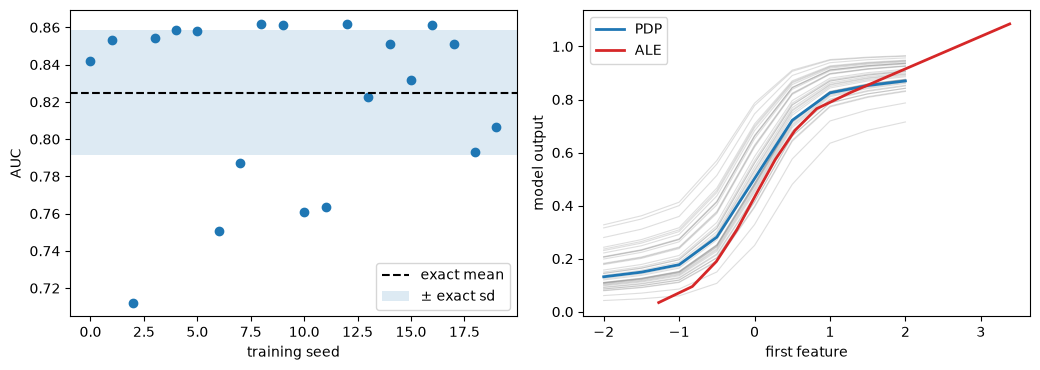

In [10]:
# Left: AUC per seed against the exact mean and spread; right: ICE, PDP and ALE of the first feature
plant, data, disp = dispersion["unstable"]
auc_by_seed = [float(disc.disc_auc(plant.train(s)(data["X"]), data["y"]).metric) for s in SEEDS]
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 3.8))
left.plot(SEEDS, auc_by_seed, "o")
exact = plant.truth()
left.axhline(exact["mean_auc"], color="black", linestyle="--", label="exact mean")
left.axhspan(exact["mean_auc"] - exact["sd_auc_across_seeds"], exact["mean_auc"] + exact["sd_auc_across_seeds"], alpha=0.15, label="± exact sd")
left.set_xlabel("training seed")
left.set_ylabel("AUC")
left.legend()
for curve_i in ice[:40]:
    right.plot(grid, curve_i, color="tab:gray", alpha=0.25, linewidth=0.8)
right.plot(grid, pdp, color="tab:blue", linewidth=2, label="PDP")
right.plot(edges[1:], ale + pdp.mean(), color="tab:red", linewidth=2, label="ALE")
right.set_xlabel("first feature")
right.set_ylabel("model output")
right.legend()
fig.tight_layout()
plt.show()

## Results

- **A stable AUC is not a stable model.** On the unstable plant the AUC over 20 seeds has a mean of 0.8221 and a spread of 0.04564 (red; the exact values are 0.8249 and 0.03354, and 20 seeds on one sample of 5,000 rows give only a rough match); on the stable plant the spread is 0. The committed LightGBM and XGBoost models have a spread of 0.00105 and 0.00079, both green, yet **62.21% and 56.72% of the obligors change grade** between at least two of the 20 seeds. The plant shows the same split: 89.18% of the obligors of the unstable plant change grade, 0% of the stable one. A validator who reads only the AUC dispersion would pass a model whose grades depend on the seed.
- **The ranking of the attributions is more stable than the reasons.** On the linear-logit family (coefficients moved by 0.15) the Kendall tau between the importance rankings of two refits averages 0.7108, with a minimum of 0.2857. The top four reasons of an obligor overlap by 0.8105 on average (5th percentile 0.6766) when read as signed contributions toward default, and by 0.8019 (5th percentile 0.6413) when the same attributions are read by absolute value. In the committed models the mean tau is 0.9253 (LightGBM) and 0.9271 (XGBoost) but the reason-code overlap is 0.7268 and 0.7121: amber for both, because a stable global ranking does not make the top four of each obligor stable.
- **Additivity is exact for a linear model and is checked, not assumed.** The gap is 1.776e-15 for the exact attributions (green) and 1.000e-06 when one column is shifted by that amount (red against the tolerance 1e-9): the test reads the shift without error. In the committed document the LightGBM attributions add up to the margin with a gap of 5.329e-15 (green) and the XGBoost ones with a gap of 1.750e-06 (red). The document does not state why, and this notebook does not claim a cause.
- **PDP, ICE and ALE obey their identities.** The PDP equals the mean of the ICE curves (to 1e-12), the ALE has 11 edges for 10 bins and a count-weighted mean of 0, and it rises with the first feature as the model does. Where the features are correlated the ALE and the PDP are different quantities, so a validator who uses one explainer to check the other should say which is which.
- **The two explainers agree on the leading features and less on all of them.** The rank correlation of the mean absolute SHAP and the ALE range is 0.9394 on the ten leading features and 0.5203 on all 20 (amber, rebuilt through the engine to the committed light). `PAY_0` raises the effect and `LIMIT_BAL` lowers it, both with the expected sign and no violation of monotonicity.

What the results do not show: the family of linear-logit models and the two plants are synthetic and their instability is chosen; the Shapley values of a tree ensemble are computed by the pipeline with the pinned `shap`, not here; and the cut points (0.01 and 0.02, 0.80 and 0.60, 0.70 and 0.40) are conventions, not regulatory thresholds.

## Summary

- Three things must stay put when only the seed changes: the AUC, the grade of each obligor and the explanation; the engine measures the AUC spread (ddof 1), the share of obligors whose grade changes and the Kendall tau of the attribution ranks.
- A reason code is a signed contribution toward default on the log-odds scale; the top four are compared across refits, and a large negative attribution is never a reason.
- Shapley attributions must add up to the prediction; the check reads the largest gap against 1e-9.
- PDP is the mean of the ICE curves; ALE accumulates local differences, is centred to mean zero and is the safer description when features are correlated.
- Explainers are checked against each other (Spearman rho) and against the expected sign and monotonicity of an effect.
- In the committed C20 sweep the AUC spread is green for both learners while more than half of the obligors change grade and the reason codes are amber, all baked with riskvalidation 0.8.1.

**What to try next.** Notebook 04 asks what a model can promise about the next window (conformal sets) and how to estimate its AUC before the defaults have matured.

## References

- ECB (2025), Guide to internal models, the paragraphs on the randomness of the training process, overfitting, explainability and the justification of complexity (43, 59, 60, 62, 64 to 66). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.supervisory_guide202507.en.pdf
- Lundberg, S. M. and Lee, S.-I. (2017), A unified approach to interpreting model predictions, NeurIPS, arXiv 1705.07874. https://arxiv.org/abs/1705.07874
- Lundberg, S. M. et al. (2020), From local explanations to global understanding with explainable AI for trees, Nature Machine Intelligence 2(1). https://doi.org/10.1038/s42256-019-0138-9
- Friedman, J. H. (2001), Greedy function approximation: a gradient boosting machine, Annals of Statistics 29(5). https://doi.org/10.1214/aos/1013203451
- Goldstein, A., Kapelner, A., Bleich, J. and Pitkin, E. (2015), Peeking inside the black box: visualizing statistical learning with plots of individual conditional expectation, Journal of Computational and Graphical Statistics 24(1). https://doi.org/10.1080/10618600.2014.907095
- Apley, D. W. and Zhu, J. (2020), Visualizing the effects of predictor variables in black box supervised learning models, Journal of the Royal Statistical Society B 82(4). https://doi.org/10.1111/rssb.12377
- EBA (2023), Follow-up report on machine learning for IRB models, EBA/REP/2023/28. https://www.eba.europa.eu/sites/default/files/document_library/Publications/Reports/2023/1061483/Follow-up%20report%20on%20machine%20learning%20for%20IRB%20models.pdf
- Yeh, I-C. and Lien, C-H., Default of credit card clients, UCI Machine Learning Repository (CC BY 4.0), the Taiwan cards of the C20 variants. https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients